### Table of Contents

A. [Research Question](#A.-Research-Question)

B. [Data Collection](#B.-Data-Collection)

C. [Data Extraction and Preparation](#C.-Data-Extraction-and-Preparation)

D. [Analysis](#D.-Analysis)

E. [Data Summary and Implications](#E.-Data-Summary-and-Implications)

F. [Sources](#F.-Sources)

### A. Research Question

This project will attempt to build a time series forecast of US electricity prices, measured in dollars per kilowatt hour (kw/H), using monthly average electricity price data from March 2016 through March 2026. This data will be sourced from the Federal Reserve Bank of St. Louis (“FRED”). 

The research question that this analysis will seek to answer is as follows: "Can the average monthly price of electricity in the United States be accurately forecast, based on historic electricity pricing data?"

The hypotheses for this analysis are as follows:

**Null Hypothesis:** A time series forecast for electricity prices in the US, with a mean absolute percentage error (MAPE) of less than 10%, cannot be created by utilizing historical electricity pricing data.

**Alternative Hypothesis:** A time series forecast for electricity prices in the US, with a mean absolute percentage error (MAPE) of less than 10%, can be created by utilizing historic electricity pricing data.

The method for evaluating the performance of the forecast will be mean absolute percentage error, or MAPE. This is one of several methods that are commonly used to evaluate time series forecasting models (ApX Machine Learning, 2025). If the resulting MAPE is 10% or more, the analysis will fail to reject the null hypothesis; a value below 10% will allow the null hypothesis to be rejected, and the alternative hypothesis to be adopted.

The price of electricity is a crucial factor in the economic health of a country. A study by the Organization for Economic Co-operation and Development (OECD) indicated that a 10% increase in energy prices could suppress a nation’s economic growth by roughly 0.15%, with larger effects seen for more energy-intensive economies (Huntingon & Liddle, 2022). The importance of electricity and its associated cost is increasing with the advent of artificial intelligence, which itself is a key driver in the US economy; power-hungry AI datacenters place “significant pressure on local electricity markets”, leading to “sharp increases in household electricity prices" (Bensaidani & Devaux, 2026). Understanding past trends in electricity pricing, as well as forecasting that pricing, would be beneficial to both individuals as well as the industries that rely on electricity for their regular operations.

### B. Data Collection

In order to perform this analysis, data was collected for the monthly average price of electricity in U.S. cities for the period of March 2016 through March 2026. The data was sourced from the Federal Reserve Bank of St. Louis (“FRED”); specifically, from their dataset APU000072610, titled “Average Price: Electricity per Kilowatt-Hour in U.S. City Average.” The dataset was downloaded directly from the FRED website.

The dataset hosted on the FRED website contains monthly average electricity prices going back to November of 1978, although this analysis will only extract the ten years of data from March 2016 through March 2026. The date range was be selected using the FRED website user interface before downloading the file, meaning that the data came already pre-filtered to the desired timeframe.

The data was provided from the FRED website as a comma-delimited (.csv) file. This file has two columns: “observation_date”, which contains the date of the observed electricity price in YYYY-MM-DD format; and “APU000072610”, which is the average price of electricity for the given month and year, measured in US dollars per kilowatt-hour out to three decimal places. The observation_date always falls on the first of the month. There are 121 records in the dataset.
 
FRED itself sourced this data from the U.S. Bureau of Labor Statistics, who in turn was provided the data by the U.S. Department of Energy; the U.S. DoE collected the original data using mail questionnaires (U.S. Bureau of Labor Statistics, 2026). The data provided on the FRED website is free and open for use for personal and non-commercial purposes, as long as FRED is correctly cited as the data source, as specified by FRED’s own “Legal Notices, Information and Disclaimers” page (FRED, 2026).

Advantages of sourcing this data from FRED include the ease by which the data can be accessed, the relatively lax restrictions placed on its use for academic and research purposes by the associated license, and the FRED website's ability to pre-filter the data down to the specified date range. A disadvantage to using this data source is its lack of specificity; the data provided collected by the BLS reflects different consumption amounts and residential rate schedules, meaning that it is "generally not suitable for use in place-to-place price comparisons" (U.S. Bureau of Labor Statistics, 2026). This limits the usefulness of the data to showing generalized pricing trends over time and restricts this analysis from performing comparative pricing across locations or geographies within the United States.

There were no specific challenges encountered in the course of sourcing this data; as detailed above, the data is easily accessible on the FRED website, publicly available for download, and can even be pre-filtered to the desired date ranges before downloading. 

### C. Data Extraction and Preparation

Before proceeding further, the necessary libraries and packages to perform this analysis will be imported below. A detailed description of these tools will be included as necessary in the following two sections (C. Data Extraction and Preparation; and, D. Analysis).

In [1]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
# scikit-learn
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, mean_absolute_error
# statsmodels
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
# autoarima
from pmdarima import auto_arima

This analysis will be performed in a Jupyter Notebook environment using the Python programming languages. Additionally, for data extraction and preparation, this analysis will make use of the Pandas package. A detailed description of these tools follows:

1. Jupyter Notebooks were chosen for this analysis because of their ability to incorporate both code and markdown, allowing for the Notebook to contain written explanations of the analysis being performed alongside the code itself. All data manipulation and analysis will take place within this Jupyter Notebook. A downside of Jupyter Notebooks is that they are not particularly suited for collaborative efforts; merging changes contributed by multiple analysts can sometimes lead to file corruption or loss of work (de Vries, 2024).

2. Python is an open-source programming language that is widely used for data manipulation across the analytics and data science industries. Because Python is open-source, it is free to use and is therefore more accessible than other competing paid tools such as SAS. Python also has access to a number of powerful libraries and packages that are purpose-built for analytics and machine learning that will be useful for this analysis. One disadvantage to Python is that it can be slow compared to lower-level languages, such as C or Java (GeeksforGeeks, 2025).

3. The Pandas library for Python allows the storage and manipulation of data inside of objects called dataframes; these act as objects for storing tabular data formatted into columns and rows, similar to Excel spreadsheets or tables in a relational database. The data from FRED is provided as a .csv that could be easily stored into a dataframe. A downside to Pandas is that it can be memory-intensive to use, particularly with larger datasets (Patil, 2023).

The code below imports the dataset to be analyzed into a Pandas dataframe. It then returns some summary statistics about that dataframe, including details about the number and name of the columns, the count of non-null values within each column, the datatype of each column, and a sample of the first five records. The code also prints the earliest and most recent dates from the dataset, to ensure that the ten-year time period is properly represented in the data.

In [2]:
# Import time series data
fred = pd.read_csv('data/APU000072610.csv')

# Inspect input file
print(fred.info())
print(fred.head())
print('Start date: ', min(fred['observation_date']))
print('End date: ', max(fred['observation_date']))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  121 non-null    object 
 1   APU000072610      120 non-null    float64
dtypes: float64(1), object(1)
memory usage: 2.0+ KB
None
  observation_date  APU000072610
0       2016-03-01         0.134
1       2016-04-01         0.134
2       2016-05-01         0.133
3       2016-06-01         0.138
4       2016-07-01         0.139
Start date:  2016-03-01
End date:  2026-03-01


In order to perform a time series analysis, the dataset must be converted into a time series dataset that can then be fed into the SARIMA model. The Python code below converts the observation_date column into a datetime datatype, then sets that column as the index for the dataset.

The summary details above also show that a single value is missing in the pricing column (APU000072610). The code below drops this observation, as missing or null observations should not be used when building out the forecast model. As we are dealing with monthly averages over a ten-year period, a single missing month should not significantly impact the quality of the analysis; therefore, dropping this record is a valid approach to cleaning the data.

After performing the above functions, the code below prints summary statistics for the time series dataset. This shows that the null observation has been effectively dropped, and the observation_date is now the index for the dataframe.

In [3]:
# Set the observation_date column as the dataframe index
fred_ts = fred
fred_ts['observation_date'] = pd.to_datetime(fred_ts['observation_date'])
fred_ts.set_index('observation_date', inplace=True)
fred_ts = fred_ts.dropna()

print(fred_ts.info())
print(fred_ts.head())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 120 entries, 2016-03-01 to 2026-03-01
Data columns (total 1 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   APU000072610  120 non-null    float64
dtypes: float64(1)
memory usage: 1.9 KB
None
                  APU000072610
observation_date              
2016-03-01               0.134
2016-04-01               0.134
2016-05-01               0.133
2016-06-01               0.138
2016-07-01               0.139


Finally, training and testing datasets will be created from the time series dataset. This involves splitting the first 75% of records into the traing dataset, and the remaining 25% of the records into the testing dataset. The training dataset will be used to build the SARIMA model; the testing dataset will be used to evaluate the performance of the SARIMA forecast against the actual historic electricity pricing data for the same date range. The code also prints the shape of each of the training and testing datasets, in order to confirm that the data was split correctly.

In [4]:
# Split training and test data
train = fred_ts.iloc[:-30] #assign all other data to train
test = fred_ts.iloc[-30:] #set aside ~25% of the dataset for test
print(train.shape, test.shape)

(90, 1) (30, 1)


### D. Analysis

The analysis below will implement a Seasonal Autoregressive integrated Moving Average (SARIMA) model to create a forecast of average electricity prices in the United States. SARIMA is an appropriate model to use for forecasting data with a seasonal component (Artley, 2022), which the below analysis shows this dataset does have. One limitation of SARIMA is that it is generally considered less effective for long-term forecasts - in ARIMA-based models like SARIMA, forecast errors can compound over time, leading to decreasing accuracy over longer timeframes (Lin, 2024).

The performance of the forecast model will be evaluated using the Mean Absolute Percentage Error (MAPE), which calculates the average absolute percentage difference between the model’s predicted values and the actual, observed values. 
MAPE is commonly used to evaluate the predictive accuracy of time series forecasts. MAPE is scale-independent and is relatively easy to explain to non-technical audiences, although it can be sensitive to values of zero in the actual data (ApX Machine Learning, 2026; GeeksforGeeks, 2025).

The following Python packages will be used to analyze the data, then build and evaluate the SARIMA model:

1. Matplotlib, which is a data visualization package for Python. This analysis will make use of the Matplotlib package to plot the electricity pricing data from FRED, as well as the predicted electricity prices generated by the SARIMA model. Matplotlib is a good option for building straightforward data visualizations, although a downside is that interactive plots are more difficult to implement and require additional coding (Bishnoi, 2024).

2. Scikit-Learn is a powerful machine learning package for Python; in this analysis, it will be used to calculate performance metrics, such as the mean absolute percentage error, to determine the accuracy of the forecast. A disadvantage to scikit-learn is that it is considered by some to be ill-suited for complex data pipelines in production environments (Chevalier, 2020).

3. Statsmodels is a statistics-focused Python module that provides a wide variety of functions for performing statistical analyses. In this analysis, Statsmodels will be used to decompose the time series data in order to display its component features, such as trend and seasonality. Statsmodels will also be used to build the SARIMA model itself. The downside to statsmodels is its steeper learning curve, which can be difficult for some (Ninad, 2025).

4. Pmdarima is a package containing functions for time series analysis in Python. This analysis will specifically make use of pmdarima’s auto_arima function, which can automatically determine the optimal parameters for a time series model, including SARIMA. The disadvantage to pmdarima is that it can sometimes have larger variances in accuracy versus other, similar packages, and also can struggle when analyzing hourly data (Mergenthaler, 2022).

Jupyter Notebooks, Python, and the Pandas library will also be used as part of this analysis; an explanation of each, along with their potential downsides, were provided in the previous section.

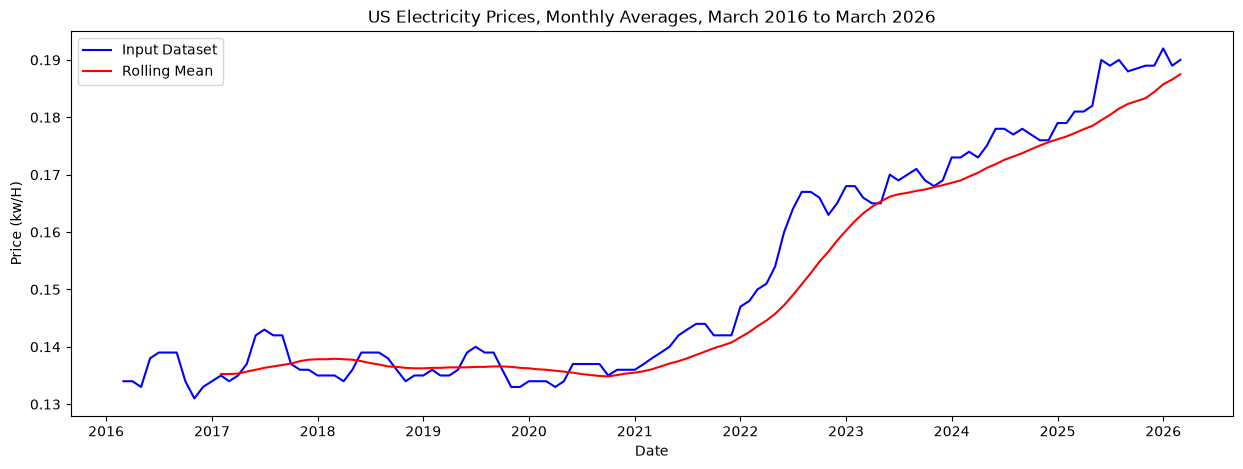

In [5]:
# Calculate rolling average
# One-month (thirty-day) window
roll_mean = fred_ts.rolling(window=12).mean()

# Use matplotlib to plot the time series
plt.figure(figsize=[15,5])
plt.plot(fred_ts,color='Blue',label="Input Dataset")
plt.plot(roll_mean,color='Red',label='Rolling Mean')
plt.title('US Electricity Prices, Monthly Averages, March 2016 to March 2026')
plt.xlabel('Date')
plt.ylabel('Price (kw/H)')
plt.legend(loc='best')
plt.show()

A line graph showing the input dataset has been printed above. This data shows the monthly average cost of electricity, measured in dollars per kilowatt/Hour (kw/H), from March 2016 through March 2026. This graph displays the electricity pricing data, as well the rolling average over time. Visualizing the data in this way reveals what appears to be a clear upward trend to the data, indicating that the data is not stationary. Additionally, there is a large jump in pricing during 2022.

Decomposing the data could show additional features of the dataset more clearly, such as trend and seasonality. The decomposed time series has been printed below.

Figure(640x480)


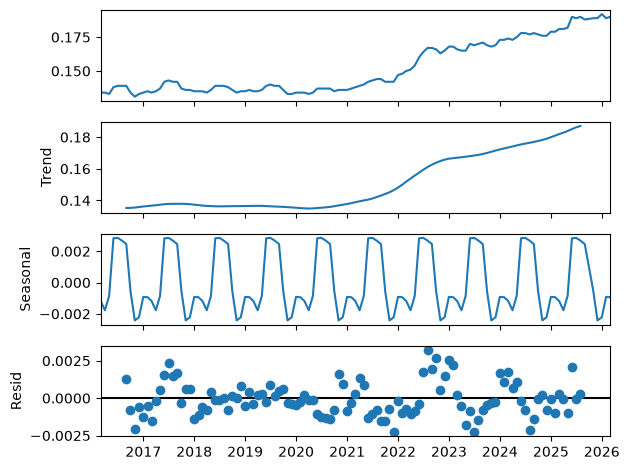

In [6]:
decomp = seasonal_decompose(fred_ts, period=12)
print(decomp.plot())

The decomposition above includes plots of the trend, seasonality, and residuals. The aforementioned upward trend of the data is much clearer here; additionally, there appears to be strong seasonality in the data with a yearly pattern, which further strengthens the case for SARIMA as an appropriate analytic method for forecasting with this data. The residuals do not appear to show any clear pattern or trend.

Now that the initial analysis has revealed the features of the data, a SARIMA model can be created based on the training dataset created above. Below, the auto_arima function is called using the training dataset. Auto_arima identifies the optimal parameters for creating an ARIMA forecasting model by iterating through different implementations of the model and evaluating the Akaike Information Criterion (AIC) for each, which is a value that can be used to measure the relative quality of statistical models against each other (Statistics HowTo, n.d.). The model with the lowest AIC is returned as the optimal model to use, given the supplied dataset and initial parameters. (Smith, n.d.)

The auto_arima function below is called with the following parameters:

- m=12, which indicates a 12-month (yearly) seasonal differencing;
- d=None, which allows auto_arima to automatically determine the optimal order of differencing for the time series;
- D=1, which sets the order of seasonal differencing to 1, thereby enforcing auto_arima to consider seasonality in the data;
- with_intercept=True, which allows auto_arima to consider the trend data in its analysis;
- trace=True, which tells auto_arima to print out statuses as it evaluates each model.

In [7]:
# Auto-ARIMA

stepwise_fit=auto_arima(train,
                        m=12,
                        d=None,
                        D=1,
                        with_intercept=True,
                        trace=True)
stepwise_fit.summary()

Performing stepwise search to minimize aic


 ARIMA(2,1,2)(1,1,1)[12] intercept   : AIC=-693.613, Time=0.73 sec
 ARIMA(0,1,0)(0,1,0)[12] intercept   : AIC=-757.394, Time=0.08 sec


 ARIMA(1,1,0)(1,1,0)[12] intercept   : AIC=-770.679, Time=0.49 sec


 ARIMA(0,1,1)(0,1,1)[12] intercept   : AIC=-773.908, Time=0.40 sec
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=-759.354, Time=0.02 sec
 ARIMA(0,1,1)(0,1,0)[12] intercept   : AIC=-757.266, Time=0.10 sec


 ARIMA(0,1,1)(1,1,1)[12] intercept   : AIC=-763.444, Time=0.35 sec


 ARIMA(0,1,1)(0,1,2)[12] intercept   : AIC=-774.948, Time=0.65 sec


... (4 outputs left out)

 ARIMA(1,1,0)(0,1,2)[12] intercept   : AIC=-754.435, Time=0.53 sec


 ARIMA(1,1,2)(0,1,2)[12] intercept   : AIC=-757.128, Time=1.09 sec


 ARIMA(0,1,1)(0,1,2)[12]             : AIC=-755.239, Time=0.66 sec

Best model:  ARIMA(0,1,1)(0,1,2)[12] intercept
Total fit time: 8.161 seconds


<class 'statsmodels.iolib.summary.Summary'>
"""
                                        SARIMAX Results                                        
===============================================================================================
Dep. Variable:                                       y   No. Observations:                   90
Model:             SARIMAX(0, 1, 1)x(0, 1, [1, 2], 12)   Log Likelihood                 392.474
Date:                                 Mon, 16 Nov 2026   AIC                           -774.948
Time:                                         13:37:01   BIC                           -763.229
Sample:                                     03-01-2016   HQIC                          -770.261
                                          - 08-01-2023                                         
Covariance Type:                                   opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0001   8.38e-05      1.540      0.124   -3.52e-05       0.000
ma.L1          0.1044      0.121      0.861      0.389      -0.133       0.342
ma.S.L12      -0.6295      0.252     -2.494      0.013      -1.124      -0.135
ma.S.L24      -0.1735      0.260     -0.668      0.504      -0.682       0.335
sigma2      1.896e-06   5.01e-07      3.785      0.000    9.14e-07    2.88e-06
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                 3.61
Prob(Q):                              0.99   Prob(JB):                         0.16
Heteroskedasticity (H):               2.30   Skew:                             0.41
Prob(H) (two-sided):                  0.04   Kurtosis:                         3.67
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

Auto_arima has determined that the optimal model for this analysis is SARIMAX(0,1,1,)(0,1,2)[12] with intercept. The model with these hyperparameters had the lowest AIC score of any model evaluated, with an AIC of -774.957. 

The Python code below implements the SARIMA model using the training dataset and the optimal hyperparameters identified by auto_arima above. The value of freq is set to MS, or "month start," as the observation_date in the data is always the first of the month. Trend is set to 'c', which tells the SARIMA model to include an intercept in order to capture the trends within the data effectively.

Note that, although the function being called is SARIMAX, the true model being developed is SARIMA. The X in SARIMAX indicates exogenous (external) data, which does not exist for this analysis.

In [8]:
# Build model from training data, with values determined by auto_arima above and frequency set to MS (Month Start)
model = SARIMAX(train, 
                order=(0,1,1), 
                seasonal_order=(0,1,2,12), 
                freq='MS', 
                trend='c')
sarimax_results = model.fit()
sarimax_results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                        SARIMAX Results                                        
===============================================================================================
Dep. Variable:                            APU000072610   No. Observations:                   90
Model:             SARIMAX(0, 1, 1)x(0, 1, [1, 2], 12)   Log Likelihood                 392.474
Date:                                 Mon, 16 Nov 2026   AIC                           -774.948
Time:                                         13:37:01   BIC                           -763.229
Sample:                                     03-01-2016   HQIC                          -770.261
                                          - 08-01-2023                                         
Covariance Type:                                   opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0001   8.38e-05      1.540      0.124   -3.52e-05       0.000
ma.L1          0.1044      0.121      0.861      0.389      -0.133       0.342
ma.S.L12      -0.6295      0.252     -2.494      0.013      -1.124      -0.135
ma.S.L24      -0.1735      0.260     -0.668      0.504      -0.682       0.335
sigma2      1.896e-06   5.01e-07      3.785      0.000    9.14e-07    2.88e-06
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                 3.61
Prob(Q):                              0.99   Prob(JB):                         0.16
Heteroskedasticity (H):               2.30   Skew:                             0.41
Prob(H) (two-sided):                  0.04   Kurtosis:                         3.67
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

Now that the SARIMA model has been built, the performance of the model can be measured by comparing the forecast data against the observed data in the test dataset. The Python code below prints a line chart showing historical electricity pricing data, and the electricity prices as predicted by the SARIMA model, over the last 30 months. This line chart includes confidence intervals in cyan, to show the range in which the model expected prices to fall.

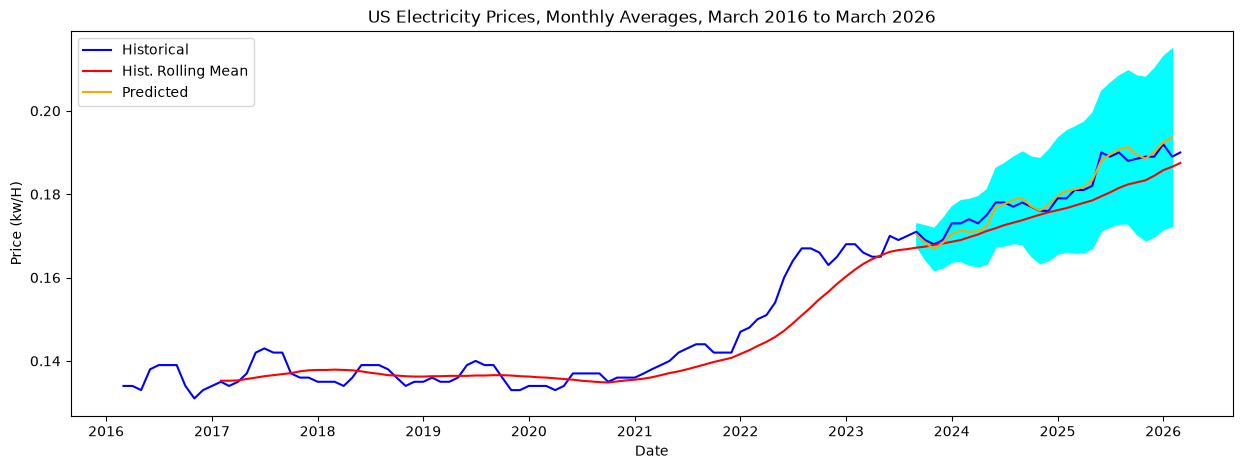

In [9]:
forecast_steps = 30
forecast = sarimax_results.forecast(steps=forecast_steps)

diff_fcast = sarimax_results.get_forecast(steps=forecast_steps)
conf_intervals = diff_fcast.conf_int()
lower_limits = conf_intervals.loc[:,'lower APU000072610']
upper_limits = conf_intervals.loc[:,'upper APU000072610']

plt.figure(figsize=[15,5])
plt.title('US Electricity Prices, Monthly Averages, March 2016 to March 2026')
plt.xlabel('Date')
plt.ylabel('Price (kw/H)')
plt.plot(fred_ts, label='Historical', color='blue')
plt.plot(roll_mean, label='Hist. Rolling Mean', color='Red')
plt.plot(forecast, label='Predicted', color='orange')
plt.fill_between(conf_intervals.index, conf_intervals['lower APU000072610'], conf_intervals['upper APU000072610'], color = 'cyan')
plt.legend()
plt.show()

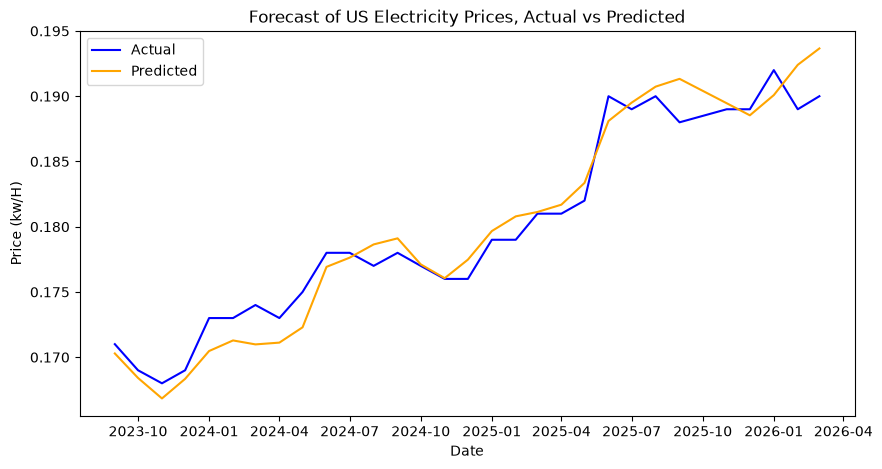

In [10]:
# Prediction dataset
start = len(train)
end = len(train)+len(test)-1
pred=sarimax_results.predict(start=start,end=end)
pred.index=fred_ts.index[start:end+1]

# Print line graph of just predicted vs actual values for the prediction date range
plt.figure(figsize=[10,5])
plt.title('Forecast of US Electricity Prices, Actual vs Predicted')
plt.xlabel('Date')
plt.ylabel('Price (kw/H)')
plt.plot(test['APU000072610'], label='Actual', color='blue')
plt.plot(pred, label='Predicted', color='orange')
plt.legend()
plt.show()

A close-up line chart, showing just the 30 months of forecasted values against the observed values, is printed above. Visually, the predicted values and the actual values seem to be very close, with both following similar trends.

The code below calculates the mean absolute percentage error (MAPE) for the forecast. The lower the MAPE, the closer the predicted values are to the actual values. A low MAPE typically indicates a stronger predictive model (GeeksforGeeks, 2025).

In [11]:
# Calculate and print MAPE
mape = mean_absolute_percentage_error(pred,test['APU000072610'])
print("Mean Absolute Percentage Error: ", mape)

Mean Absolute Percentage Error:  0.007723195981502806


### E. Data Summary and Implications

The research question for this analysis was, "Can the average monthly price of electricity in the United States be accurately forecast, based on historic electricity pricing data?" The SARIMA model created above was trained on historic electricity pricing data, and displays strong forecasting capabilities when applied against the test data, showing an ability to forecast electricity prices over time with minimal error. In fact, the model was capable of forecasting the last 30 months of electricity pricing data from the original dataset with a mean absolute percentage error of just 0.772%; put plainly, this means that the average difference between the forecasted electricity prices, and the actual observed electricity prices, was just 0.772%. 

To reiterate, the hypotheses for this analysis were as follows:

**Null Hypothesis:** A time series forecast for electricity prices in the US, with a mean absolute percentage error (MAPE) of less than 10%, cannot be created by utilizing historical electricity pricing data.

**Alternative Hypothesis:** A time series forecast for electricity prices in the US, with a mean absolute percentage error (MAPE) of less than 10%, can be created by utilizing historic electricity pricing data.

As stated above, the MAPE for this forecast was less than 1%. This clearly resolves the question posed at the start of this analysis, and allows the null hypothesis to be rejected, as the threshold of 10% has been met. 

One limitation of this analysis its reliability over longer periods of time. ARIMA-based models such as SARIMA are considered less effective for long-term forecasts, as forecast errors can compound over time; the end result of this fact is a progressively less accurate forecast as the forecast period is extended (Lin, 2024).

The results of the analysis show that electricity prices are projected to increase steadily as time goes on. This will have wide effects not only to individuals and businesses, but also to the broader economy - energy-intensive economies such as the United States could see suppression of its economic growth due to rising power costs (Huntington & Liddle, 2022). This generalized economic slowdown could have knock-on effects to businesses or corporations in heavily electricity-dependent industries, such as the tech sector, as this affects not just their growth but also their operational costs. 

This analysis has shown that SARIMA is an appropriate forecasting model for the monthly average price of electricity within the United States. My recommended course of action for organizations with an interest in forecasting electricity pricing would be implementing SARIMA models for this purpose, as the model implemented here was able to return strong forecasting results using historic electricity pricing data. I would also recommend that this model be updated with new data as it becomes available, so that the forecast is constantly retrained with the most up-to-date data; additionally I would recommend limiting the forecast horizon to no more than 3 years at a time, in order to avoid the issue of compounding forecast errors inherent to ARIMA-based models.

One approach for further study of this dataset would be implementing a SARIMAX model by introducing exogenous data into the analysis - the prices of crude oil or natural gas, for example - which would allow the analysis to account for external forces that might affect electricity pricing (Artley, 2022). Another method might be performing another forecasting analysis using a different methodology, such as Long Short-Term Memory (LSTM), which is a type of neural network which specifically excels at forecasting based on historical data (Davis, 2024); the results of such an analysis could be compared to the SARIMA model to determine which would be more accurate.

### F. Sources

Anis Bensaidani, Pascal Deveaux. *Electricity prices in the U.S.: a significant economic and electoral concern in the run-up to the midterms.* Economic Research, BNP Paribas. February 10, 2026. https://economic-research.bnpparibas.com/html/en-US/Electricity-prices-significant-economic-electoral-concern-midterms-2/10/2026,53216 

ApX Machine Learning. *Common Evaluation Metrics (MAE, MSE, RMSE, MAPE).* Accessed April 26, 2025. https://apxml.com/courses/time-series-analysis-forecasting/chapter-6-model-evaluation-selection/evaluation-metrics-mae-mse-rmse

Artley, Brendan. *Time Series Forecasting with ARIMA , SARIMA and SARIMAX.* Towards Data Science. April 26, 2022. https://towardsdatascience.com/time-series-forecasting-with-arima-sarima-and-sarimax-ee61099e78f6/

Bishnoi, Kanchan. *Matplotlib or Plotly: Deciding the Champion for Your Data.* Medium.com. January 14, 2024. https://medium.com/@bishnoi.kanchan4141/matplotlib-or-plotly-deciding-the-champion-for-your-data-a9e8cbfe36f8

Chevalier, Guillaume. *What's Wrong with Scikit-Learn.* Neuraxio. January 3, 2020. https://www.neuraxio.com/blogs/news/whats-wrong-with-scikit-learn-pipelines

Davis, Jennifer. *How to Build LSTM Models for Time Series Prediction in Python.* Statology. September 6, 2024. https://www.statology.org/how-to-build-lstm-models-for-time-series-prediction-in-python/

de Vries, Erik Jan. *When and How Jupyter Notebooks Fail, and What to Use Instead.* Medium.com. October 24, 2024. https://erikjandevries.medium.com/when-and-how-jupyter-notebooks-fail-and-what-to-use-instead-a52c27dbaa4c

FRED, Federal Reserve Bank of St. Louis. *Legal Notices, Information and Disclaimers.* Retrieved April 21, 2026. https://fred.stlouisfed.org/legal/  

GeeksforGeeks. *Disadvantages of Python*. July 11, 2025. https://www.geeksforgeeks.org/python/disadvantages-of-python/

GeeksforGeeks. *Evaluating Forecast Accuracy* July 23, 2025. https://www.geeksforgeeks.org/r-language/evaluating-forecast-accuracy/

GeeksforGeeks. *SAS vs R vs Python*. July 23, 2025. https://www.geeksforgeeks.org/blogs/sas-vs-r-vs-python/

Hillard Huntington, Brantley Liddle. *How energy prices shape OECD economic growth: Panel evidence from multiple decades.* Energy Economics, Volume 111, July 2022. https://doi.org/10.1016/j.eneco.2022.106082 
(https://www.sciencedirect.com/science/article/pii/S014098832200247X)

Lin, Khin Yadanar. *Understanding the Limitations of ARIMA Forecasting.* Towards Data Science. August 21, 2024. https://towardsdatascience.com/understanding-the-limitations-of-arima-forecasting-899f8d8e5cf3/

Mergenthaler, Max. *ARIMA Experiments*. Nixtla Github. July 18, 2022. https://github.com/Nixtla/statsforecast/tree/v0.6.0/experiments/arima

Ninad. *What is Statsmodels?* AskPython. November 19, 2025. https://www.askpython.com/python-modules/statsmodel/what-is-statsmodels

Patil, Rohan. *Exploring the Pros and Cons of Pandas.* Medium.com. June 19, 2023. https://rohanjpatil01.medium.com/exploring-the-pros-and-cons-of-pandas-1675463971d4

Smith, Taylor G. *pmdarima.arima.auto_arima*. PMDARIMA Documentation. Accessed April 25, 2026. https://alkaline-ml.com/pmdarima/modules/generated/pmdarima.arima.auto_arima.html

Statistics HowTo. *Akaike’s Information Criterion: Definition, Formulas* Accessed April 25, 2026. https://www.statisticshowto.com/akaikes-information-criterion/

U.S. Bureau of Labor Statistics. *Average Price: Electricity per Kilowatt-Hour in U.S. City Average [APU000072610]*. Retrieved from FRED, Federal Reserve Bank of St. Louis, April 21, 2026.  https://fred.stlouisfed.org/series/APU000072610

U.S. Bureau of Labor Statistics *CPI: Average Price Data*. Retrieved April 25, 2026. https://www.bls.gov/cpi/factsheets/average-prices.htm